# Predicción del rendimiento FP32 en GPUs

El objetivo de este proyecto es predecir si una GPU es "de bajo, medio o alto rendimiento"

## 0. Librerias

In [174]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import userdata
from sklearn.experimental import enable_iterative_imputer  # habilita el imputador
from sklearn.model_selection import train_test_split
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

## 1. Carga de datos

### CSV desde kaggle

In [175]:
# 1. Configurar la clave API de Kaggle
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
!kaggle datasets download -d psychocoderxd/gpu-performance-prediction

# 2. Descargar y descomprimir el dataset directamente desde Kaggle
!kaggle datasets download -d psychocoderxd/gpu-performance-prediction
!unzip -o gpu-performance-prediction.zip

# 3. Cargar el dataset (unificando train/test si aplica)
df = pd.read_csv("train.csv") # o "test.csv" según corresponda

Dataset URL: https://www.kaggle.com/datasets/psychocoderxd/gpu-performance-prediction
License(s): CC-BY-NC-SA-4.0
gpu-performance-prediction.zip: Skipping, found more recently modified local copy (use --force to force download)
Dataset URL: https://www.kaggle.com/datasets/psychocoderxd/gpu-performance-prediction
License(s): CC-BY-NC-SA-4.0
gpu-performance-prediction.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  gpu-performance-prediction.zip
  inflating: test.csv                
  inflating: train.csv               


### carga y exploracion inicial

In [176]:
pd.read_csv("train.csv")

print(df.shape)

df.info()

df.head()

(10000, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                10000 non-null  int64  
 1   cores             9993 non-null   float64
 2   tensor_cores      3625 non-null   float64
 3   rt_cores          4221 non-null   float64
 4   sm_count          6003 non-null   float64
 5   base_clock        7976 non-null   float64
 6   boost_clock       7976 non-null   float64
 7   memory_clock      10000 non-null  float64
 8   ram               10000 non-null  float64
 9   bus_width         10000 non-null  float64
 10  fp16_performance  6725 non-null   float64
 11  fp32_performance  9993 non-null   float64
 12  fp64_performance  9374 non-null   float64
 13  bf16_performance  6 non-null      float64
 14  tf32_performance  6 non-null      float64
 15  int8_performance  0 non-null      float64
 16  multi_gpu         0 non-null 

,id,cores,tensor_cores,rt_cores,sm_count,base_clock,boost_clock,memory_clock,ram,bus_width,fp16_performance,fp32_performance,fp64_performance,bf16_performance,tf32_performance,int8_performance,multi_gpu,api_cuda,gpi_value
0,1748,6144.00000,192.00000,48.00000,48.00000,1575.00000,1815.00000,1188.00000,8.00000,256.00000,22.30000,22.30000,0.34850,NaN,NaN,NaN,NaN,8.60000,11.48000
1,13263,1920.00000,240.00000,30.00000,30.00000,600.00000,1215.00000,1500.00000,6.00000,192.00000,9.33100,4.66600,0.14580,NaN,NaN,NaN,NaN,7.50000,3.89000
2,1526,4864.00000,152.00000,38.00000,38.00000,1410.00000,1680.00000,1750.00000,8.00000,256.00000,16.34000,16.34000,0.25540,NaN,NaN,NaN,NaN,8.60000,9.10000
3,1862,336.00000,NaN,NaN,7.00000,NaN,NaN,850.00000,1024.00000,256.00000,NaN,0.87360,0.07280,NaN,NaN,NaN,NaN,2.10000,2.84000
4,7001,3072.00000,384.00000,48.00000,48.00000,1650.00000,1860.00000,1937.00000,8.00000,256.00000,22.86000,11.43000,0.35710,NaN,NaN,NaN,NaN,7.50000,7.63000


## 2. Diccionario de Variables


1. Identificador de la Fila
    * id: Es el identificador o número de fila de la tarjeta de video.

2. Especificaciones Técnicas y de Arquitectura
Son métricas cuantitativas sobre los componentes físicos de la GPU:

    * cores: Cantidad de núcleos principales de procesamiento (por ejemplo, núcleos CUDA o Stream Processors).

    * tensor_cores: Número de núcleos dedicados a cálculos de Inteligencia Artificial y Deep Learning.

    * rt_cores: Número de núcleos dedicados a trazado de rayos (Ray Tracing en tiempo real).

    * sm_count: Cantidad de Streaming Multiprocessors (bloques de procesamiento general de la arquitectura).

    * base_clock: Velocidad base de reloj del procesador de la GPU (en MHz).

    * boost_clock: Velocidad máxima o con turbo (boost) a la que puede operar el procesador (en MHz).

    * memory_clock: Velocidad o frecuencia de transferencia de la memoria VRAM (en MHz).

    * ram: Capacidad total de memoria VRAM (normalmente en GB).

    * bus_width: Ancho de banda del bus de memoria (medido en bits, ej: 128-bit, 256-bit, 384-bit).

3. Rendimiento en Operaciones Matemáticas (Métricas de Cómputo)
Variables que miden la potencia bruta de la tarjeta en distintas precisiones:

    * fp16_performance: Potencia en media precisión (16 bits) en TFLOPS.

    * fp32_performance: Potencia en precisión simple (32 bits) en TFLOPS. Esta es la Variable Objetivo (Target) a predecir.

    * fp64_performance: Potencia en doble precisión (64 bits) en TFLOPS (usada en cómputo científico).

4. Columnas Vacías (Sin Datos / 100% NaN):

    * bf16_performance: Potencia en Bfloat16. (Completamente vacía).

    * tf32_performance: Potencia en TensorFloat-32. (Completamente vacía).

    * int8_performance: Rendimiento en enteros de 8 bits. (Completamente vacía).

    * multi_gpu: Métrica de soporte multitarjeta. (Completamente vacía).

5. Software y Evaluación Comercial
    * api_cuda: Versión o nivel de compatibilidad con la API de cómputo CUDA de Nvidia.

    * gpi_value: Un índice o puntuación ponderada de rendimiento global del chip (GPU Performance Index).

## 3. Análisis exploratorio (EDA)

### Tipos de variables

In [177]:
# esto es por cumplpir lo que dice el pdf
# separamos las numericas y las categoricas
# igual como podemos ver en el dataset sabemos que todas van a ser numericas xd
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
print(f"Variables Numéricas ({len(numeric_cols)}): {numeric_cols}")

categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
print(f"Variables Categóricas ({len(categorical_cols)}): {categorical_cols}")

Variables Numéricas (19): ['id', 'cores', 'tensor_cores', 'rt_cores', 'sm_count', 'base_clock', 'boost_clock', 'memory_clock', 'ram', 'bus_width', 'fp16_performance', 'fp32_performance', 'fp64_performance', 'bf16_performance', 'tf32_performance', 'int8_performance', 'multi_gpu', 'api_cuda', 'gpi_value']
Variables Categóricas (0): []


### Reporte de valores nulos

In [178]:
# Definición la variable objetivo (Target)
TARGET = "fp32_performance"
print(f"Variable Objetivo definida: {TARGET}")

# Reporte de datos nulos por columna

# hacemos el null_report con dos columnas por cada categoria, una de valores
# nulos donde es la suma de estos y otro que seria el porcentaje pa visajear
null_report = pd.DataFrame({  # usamos df porque sabemos que todos son numericos
    "Valores Nulos": df.isnull().sum(),
    "Porcentaje (%)": (df.isnull().sum() / len(df)) * 100
}).sort_values(by="Porcentaje (%)", ascending=False)

display(null_report)

Variable Objetivo definida: fp32_performance


,Valores Nulos,Porcentaje (%)
int8_performance,10000,100.00000
multi_gpu,10000,100.00000
bf16_performance,9994,99.94000
tf32_performance,9994,99.94000
tensor_cores,6375,63.75000
rt_cores,5779,57.79000
sm_count,3997,39.97000
fp16_performance,3275,32.75000
api_cuda,2700,27.00000
base_clock,2024,20.24000


### Distribucion de columnas con nulos


Lote 1: ['cores', 'tensor_cores', 'rt_cores', 'sm_count']


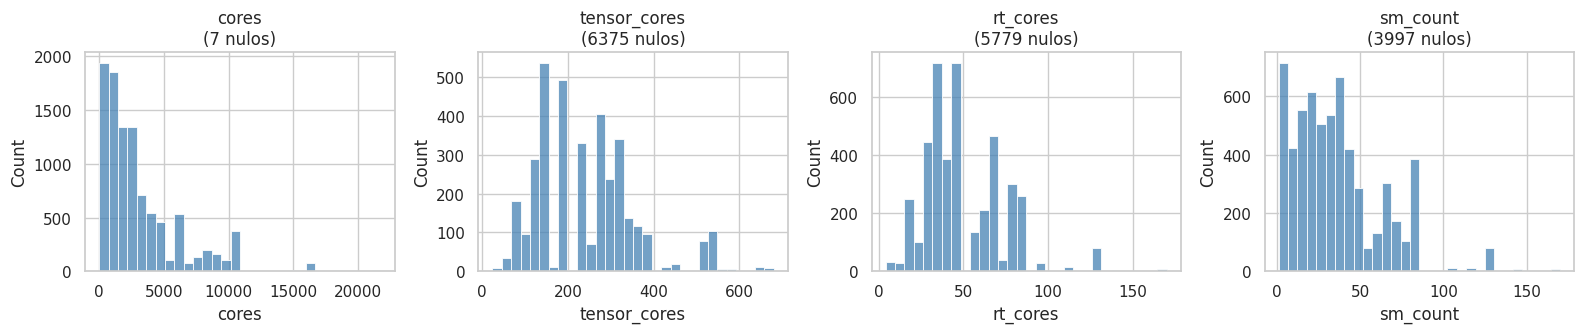

Lote 2: ['base_clock', 'boost_clock', 'fp16_performance', 'fp64_performance']


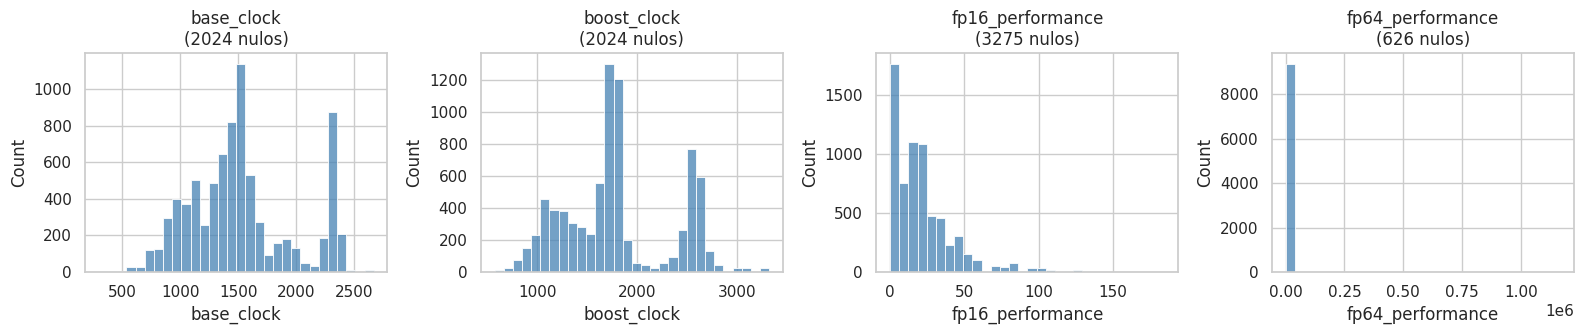

Lote 3: ['bf16_performance', 'tf32_performance', 'int8_performance', 'multi_gpu']


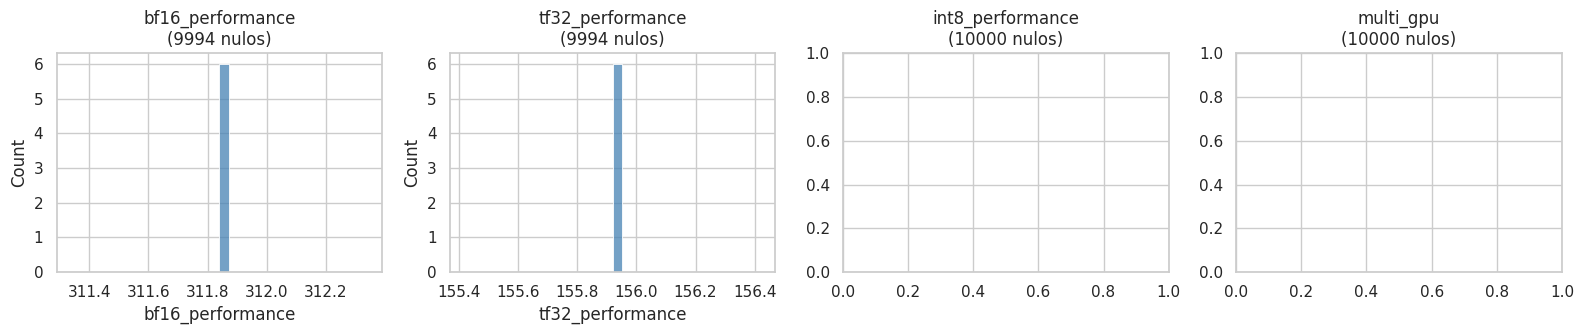

Lote 4: ['api_cuda']


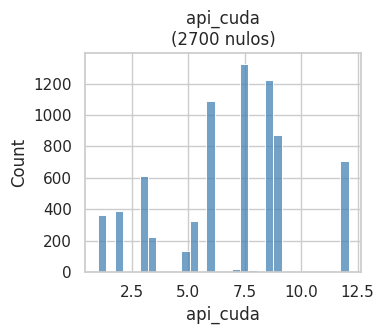

In [179]:
# Visualización de la distribucion de cada columna

# hacemos una lista con las columnas que contengan nulo excepto el id, el gpi_value y pues el target
cols_nulos = [
    c for c in df.columns
    if df[c].isnull().sum() > 0 and c not in ["id", "gpi_value", TARGET]
]

# crea y muestra gráficos de distribución (histogramas) para las columnas con
# valores nulos, organizándolos en grupos (lotes) de máximo 4 gráficos por fila.
for i in range(0, len(cols_nulos), 4):
    lote = cols_nulos[i:i+4]
    print(f"Lote {i//4 + 1}: {lote}")

    fig, axes = plt.subplots(1, len(lote), figsize=(4 * len(lote), 3.5))
    if len(lote) == 1:
        axes = [axes]

    for ax, col in zip(axes, lote):
        sns.histplot(df[col].dropna(), bins=30, kde=False,
                     ax=ax, color="steelblue")
        ax.set_title(f"{col}\n({df[col].isnull().sum()} nulos)")

    plt.tight_layout()
    plt.show()

## 4. Limpieza de datos

### Eliminación de columnas vacías

In [180]:
# eliminamos las columnas que no aportan nada porque estan vacias o practicamente sin elementos
cols_a_eliminar = ["bf16_performance", "tf32_performance", "int8_performance", "multi_gpu"]
df = df.drop(columns=[c for c in cols_a_eliminar if c in df.columns])
print("Nuevas dimesiones:", df.shape)
df.head()

Nuevas dimesiones: (10000, 15)


,id,cores,tensor_cores,rt_cores,sm_count,base_clock,boost_clock,memory_clock,ram,bus_width,fp16_performance,fp32_performance,fp64_performance,api_cuda,gpi_value
0,1748,6144.00000,192.00000,48.00000,48.00000,1575.00000,1815.00000,1188.00000,8.00000,256.00000,22.30000,22.30000,0.34850,8.60000,11.48000
1,13263,1920.00000,240.00000,30.00000,30.00000,600.00000,1215.00000,1500.00000,6.00000,192.00000,9.33100,4.66600,0.14580,7.50000,3.89000
2,1526,4864.00000,152.00000,38.00000,38.00000,1410.00000,1680.00000,1750.00000,8.00000,256.00000,16.34000,16.34000,0.25540,8.60000,9.10000
3,1862,336.00000,NaN,NaN,7.00000,NaN,NaN,850.00000,1024.00000,256.00000,NaN,0.87360,0.07280,2.10000,2.84000
4,7001,3072.00000,384.00000,48.00000,48.00000,1650.00000,1860.00000,1937.00000,8.00000,256.00000,22.86000,11.43000,0.35710,7.50000,7.63000


### Eliminación de filas con target nulo

El target `fp32_performance` **nunca se imputa**: es la variable que el modelo
debe aprender a predecir. Si inventamos sus valores con imputación, estaríamos
entrenando al modelo con datos falsos.

Por eso, las 7 filas que tienen `fp32_performance` nulo se **eliminan**
directamente del dataset.

In [181]:
n_antes = len(df)
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
print(f"Filas eliminadas por target nulo: {n_antes - len(df)}")
print(f"Nuevo shape: {df.shape}")

Filas eliminadas por target nulo: 7
Nuevo shape: (9993, 15)


### Imputación multivariada

In [182]:
# basicamente vamos a llenar los espacios que estan vacios usando IterativeImputer
# porque la que vimos en clase de con la media o la mediana no siento que sea correcta

# creamos una lista de las columnas que vammos a imputar (excluyengo el target y el id)
cols_a_imputar = [
    c for c in df.columns
    if c not in [TARGET, "id"] and df[c].isnull().sum() > 0
]
print(f"Columnas a imputar ({len(cols_a_imputar)}): {cols_a_imputar}")

# iniciamos un algoritmo de regresiones lineales para predecir los valores faltantes
# como es ciclico hacemos que haga 10 iteraciones y siempre en una semilla
# fija para la reproducibilidad (en este caso la 42 xd)
imputador = IterativeImputer(max_iter=10, random_state=42)

# con el fit_transform lo que se hace es que con el fit el modelo aprende las
# relaciones, correlacion y patrones y con el transform calcula matematicamente
# el valor mas probable y remplaza los nulos con estos valores
df[cols_a_imputar] = imputador.fit_transform(df[cols_a_imputar])

Columnas a imputar (8): ['tensor_cores', 'rt_cores', 'sm_count', 'base_clock', 'boost_clock', 'fp16_performance', 'fp64_performance', 'api_cuda']


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


### Verificacion

In [183]:
# el primer sum suma las columnas individulamente y el segundo las sumas todas
# entonces si lo anterior funciono el resultado debe ser 0 :D
print(df.isnull().sum().sum())

0


## 5. Analisis del Target

Analizamos la distribución de `fp32_performance` para entender su forma,
rango y posibles sesgos antes de modelar.

### Distribución y boxplot

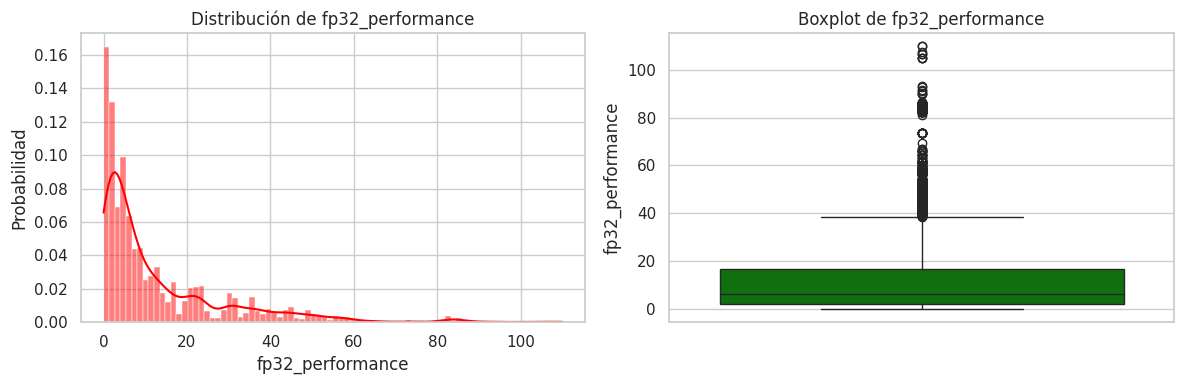

In [184]:
# Hicimos el histograma y el boxplot normal como se vio en clase
plt.figure(figsize=(12, 4))

# Histograma con KDE
ax1 = plt.subplot(1, 2, 1)
sns.histplot(
    data=df.dropna(subset=[TARGET]),
    x=TARGET,
    kde=True,
    color="red",
    stat="probability",
    ax=ax1
)
ax1.set_title(f"Distribución de {TARGET}")
ax1.set_xlabel(TARGET)
ax1.set_ylabel("Probabilidad")

# Boxplot
ax2 = plt.subplot(1, 2, 2)
sns.boxplot(data=df, y=TARGET, color="green", ax=ax2)
ax2.set_title(f"Boxplot de {TARGET}")
ax2.set_ylabel(TARGET)

plt.tight_layout()
plt.show()

### PDF y CDF empírica

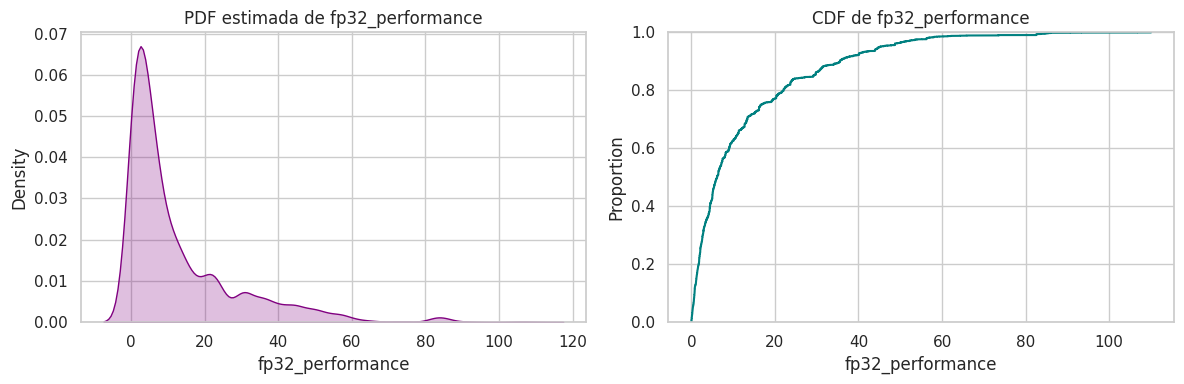

In [185]:
# lo mismo PDF y CDF que vimos en clase
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(df[TARGET].dropna(), fill=True, color="purple", ax=axes[0])
axes[0].set_title(f"PDF estimada de {TARGET}")

sns.ecdfplot(df[TARGET].dropna(), color="teal", ax=axes[1])
axes[1].set_title(f"CDF de {TARGET}")

plt.tight_layout()
plt.show()

### Estadísticas clave del target

In [186]:
# para concer los datos mas especificos los sacamos a mano
# sacamos la mediana, el primer y tercer cuartil para poder sacar la cajita
mediana = df[TARGET].median()
Q1 = df[TARGET].quantile(0.25)
Q3 = df[TARGET].quantile(0.75)
IQR = Q3 - Q1

print(f"Mediana: {mediana:.2f} TFLOPS")
print(f"Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")

# Miramos los cortes de las clases
p50 = df[TARGET].quantile(0.50)
p85 = df[TARGET].quantile(0.85)

print(f"\nSegmentación:")
print(f"  Clase Bajo  (≤ p50)      : {p50:.2f} TFLOPS")
print(f"  Clase Medio (p50 – p85)  : {p50:.2f} – {p85:.2f} TFLOPS")
print(f"  Clase Alto  (> p85)      : {p85:.2f} TFLOPS")

Mediana: 6.17 TFLOPS
Q1: 2.14 | Q3: 16.66 | IQR: 14.52

Segmentación:
  Clase Bajo  (≤ p50)      : 6.17 TFLOPS
  Clase Medio (p50 – p85)  : 6.17 – 29.15 TFLOPS
  Clase Alto  (> p85)      : 29.15 TFLOPS


### Interpretación


Observaciones:
- La distribución de `fp32_performance` es **asimétrica positiva**
  (sesgo hacia la derecha): la mayoría de GPUs se concentran en valores
  bajos (0–20 TFLOPS (un TFLOP es cuántos billones de cálculos decimales puede hacer la GPU por segundo) ) y una cola larga se extiende hacia GPUs de gama alta.
- Hay una **cola derecha pronunciada** con outliers por encima de 60 TFLOPS
- La CDF confirma esto: aproximadamente el 80% de las GPUs están por debajo
  de ~20 TFLOPS.
- Implicación para el modelo: conviene probar transformaciones
  (log, sqrt) o modelos robustos a la asimetría (fuentes deepseek xd).

## 6. Análisis de outliers

### Boxplots por feature

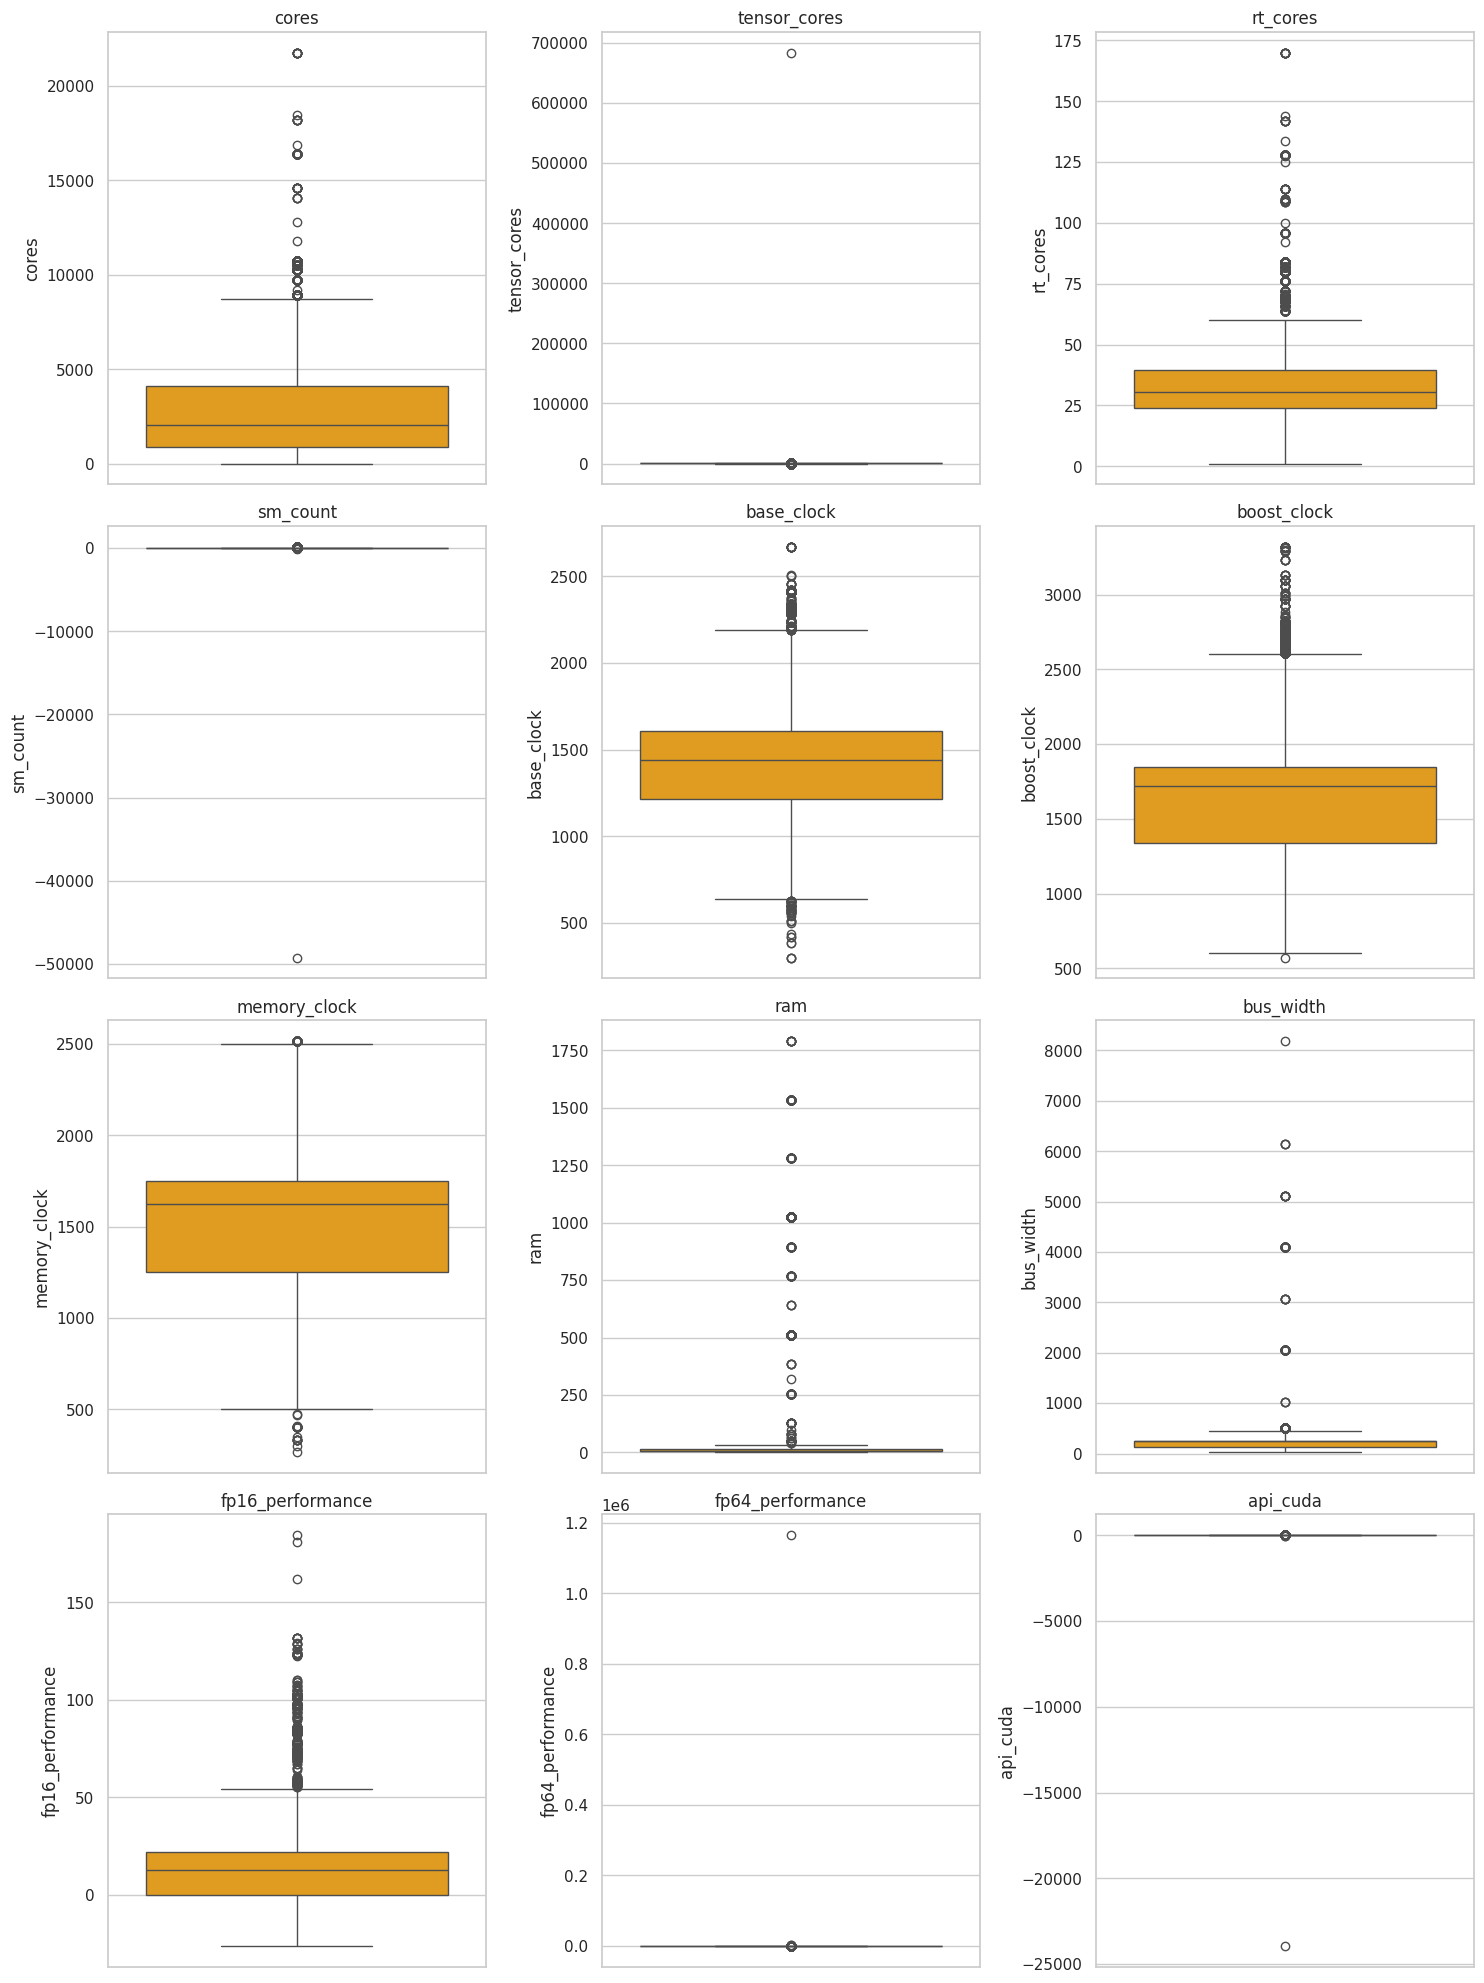

In [187]:
# creamos la lista de las variables numericas y como ya habiamos visto que todas
# era numericas simplemente sacamos las que no necesitamos
num_features = [c for c in df.columns if c not in ["id", "gpi_value", TARGET]]

# es una herramienta sorpresa que nos ayudara mas tarde
num_rows = (len(num_features) + 2) // 3 # Calcula cuántas filas de gráficos necesitamos si vemos 3 gráficos por fila

plt.figure(figsize=(15, 5 * num_rows)) # aca usamos el num_rows

# hacemos el boxplot por cada columna en la posicion que indique (i + 1)
# y le ponemos de titulo para que sea mas facil el nombre de la columna misma
for i, col in enumerate(num_features):
    ax = plt.subplot(num_rows, 3, i + 1)
    sns.boxplot(y=df[col], ax=ax, color="orange")
    ax.set_title(col)

plt.tight_layout()
plt.show()

### Histograma por feature

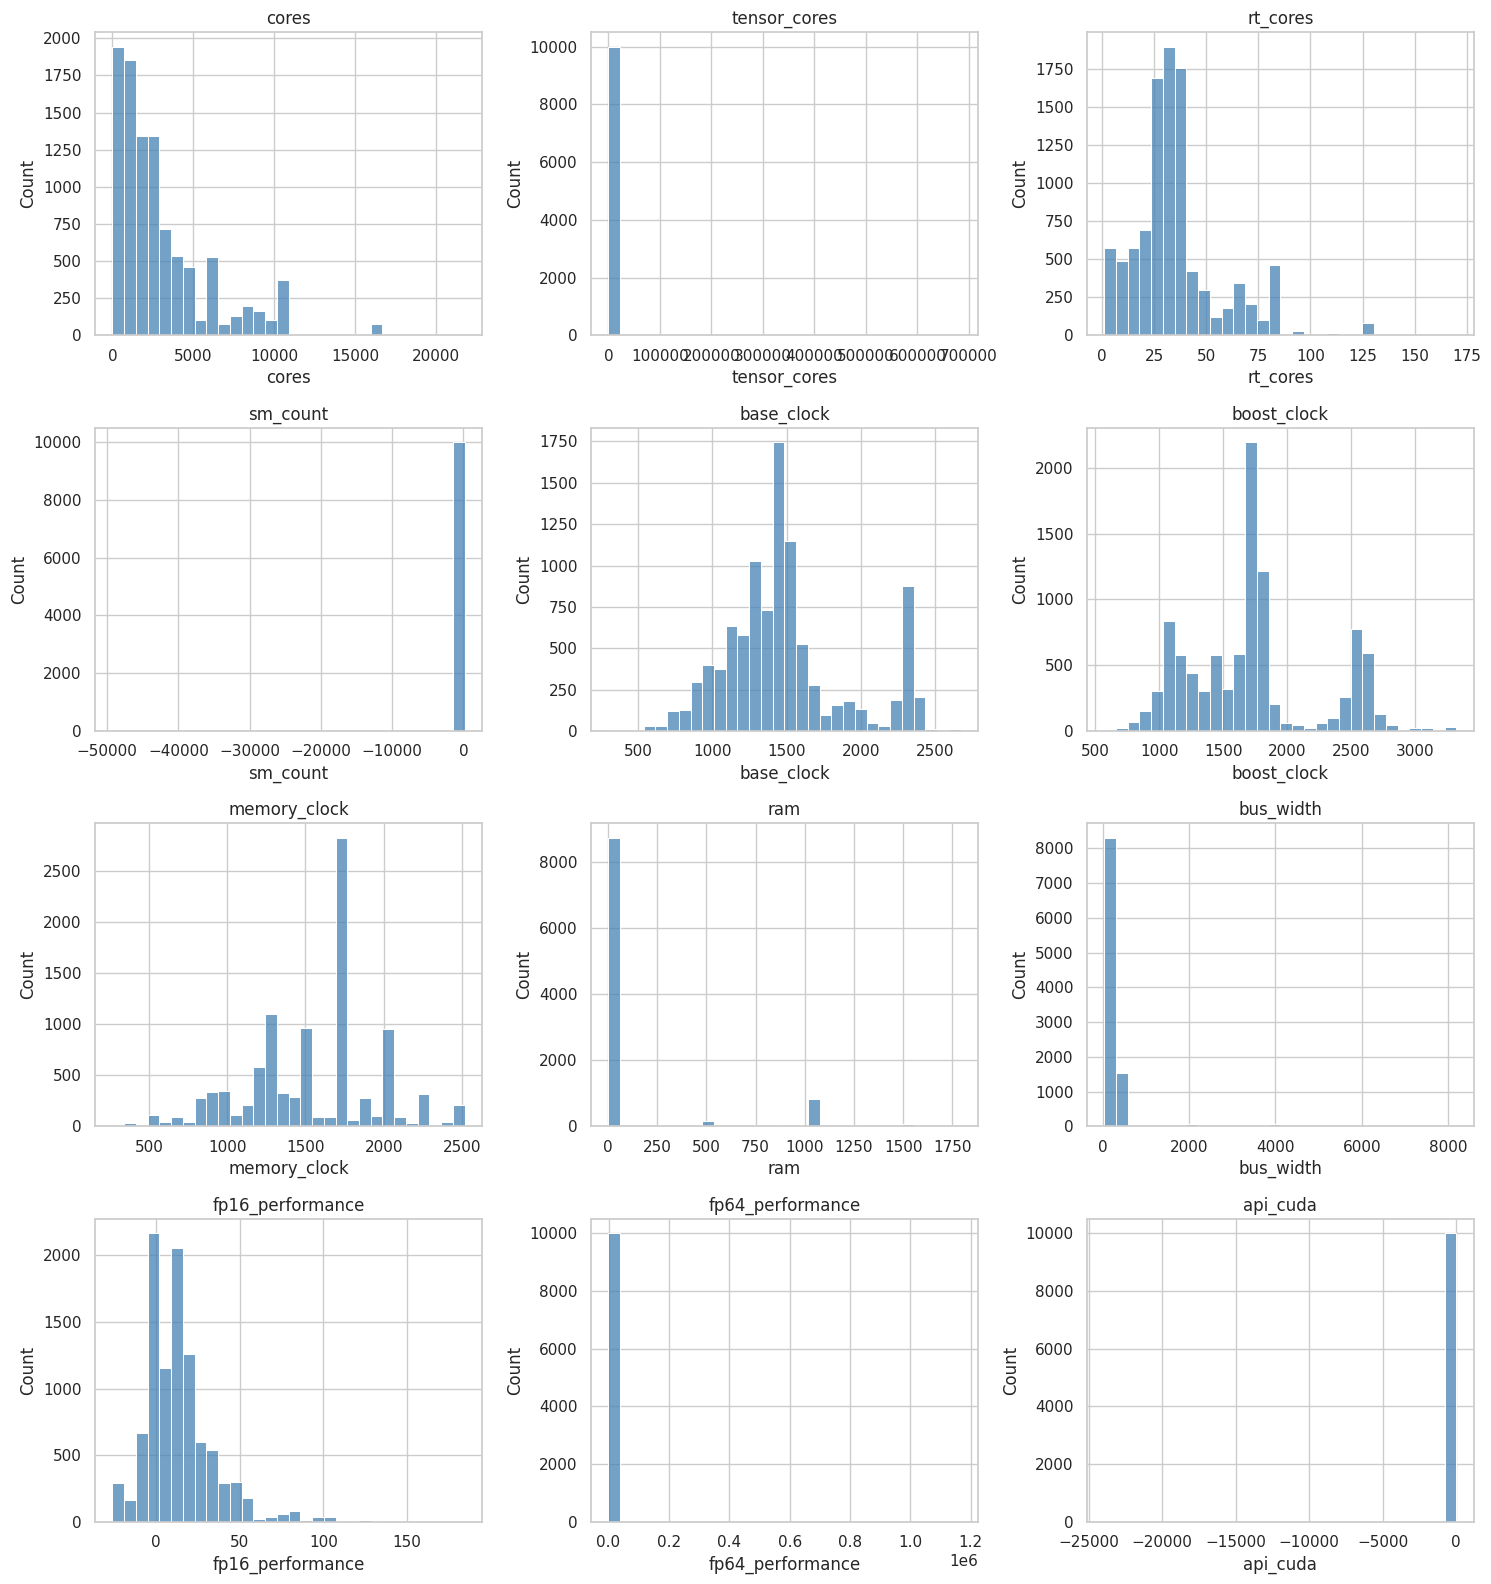

In [188]:
# reutilizamos num_features (ya excluye id, gpi_value y el target)
num_rows = (len(num_features) + 2) // 3  # 3 histogramas por fila

plt.figure(figsize=(15, 4 * num_rows))

# por cada feature dibujamos su histograma con KDE
# para ver de un vistazo la forma de la distribución (simetría, sesgo, cola)
for i, col in enumerate(num_features):
    ax = plt.subplot(num_rows, 3, i + 1)
    sns.histplot(data=df, x=col, kde=False, ax=ax, color="steelblue", bins=30)
    ax.set_title(col)

plt.tight_layout()
plt.show()

### Reporte IQR

In [189]:
# Analizamos outliers + estadísticas clave por feature
outlier_report = {}

for col in num_features:
    # Percentiles y rango intercuartílico
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1

    # Bigotes (límites de Tukey)
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

    # Contamos outliers y guardamos TODO junto
    outlier_report[col] = {
        "mediana": df[col].median(),
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "lower": lower,
        "upper": upper,
        "n_outliers": ((df[col] < lower) | (df[col] > upper)).sum()
    }

# Lo convertimos en DataFrame y ordenamos por cantidad de outliers
reporte = pd.DataFrame(outlier_report).T
reporte = reporte.sort_values("n_outliers", ascending=False)
reporte

,mediana,Q1,Q3,IQR,lower,upper,n_outliers
sm_count,30.01196,24.00000,39.22114,15.22114,1.16829,62.05285,1365.00000
base_clock,1440.00000,1216.00000,1605.00000,389.00000,632.50000,2188.50000,1346.00000
ram,8.00000,4.00000,16.00000,12.00000,-14.00000,34.00000,1278.00000
rt_cores,30.68180,24.14758,39.59566,15.44807,0.97547,62.76777,1277.00000
fp64_performance,0.26680,0.13440,0.56320,0.42880,-0.50880,1.20640,1063.00000
cores,2048.00000,896.00000,4096.00000,3200.00000,-3904.00000,8896.00000,751.00000
boost_clock,1719.94274,1340.00000,1845.00000,505.00000,582.50000,2602.50000,709.00000
fp16_performance,12.78000,0.10100,22.06000,21.95900,-32.83750,54.99850,410.00000
tensor_cores,259.71838,175.39034,320.00000,144.60966,-41.52414,536.91449,334.00000
bus_width,256.00000,128.00000,256.00000,128.00000,-64.00000,448.00000,309.00000


### Decisión

**No eliminamos outliers.** En este dataset representan GPUs de gama alta
legítimas, no errores de medición. Eliminarlos
sesgaría el modelo hacia hardware de gama media y le impediría aprender
a predecir rendimiento alto, que es justo el caso de uso más valioso.

## 7. Análisis de correlación

### Matriz de correlacion

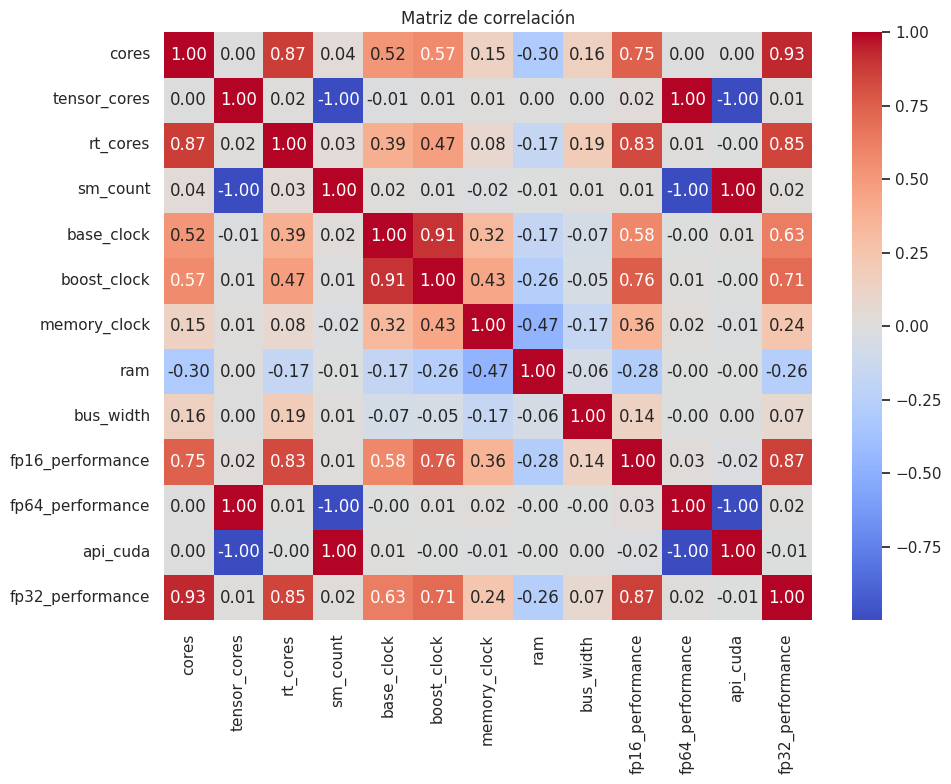

In [190]:
# Hacemos la matriz como lo que vimos en clase normal
plt.figure(figsize=(10, 8))

num_features_sin_target = [c for c in num_features if c != TARGET]
corr = df[num_features_sin_target + [TARGET]].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

### Ranking con el target

In [191]:
# Para verlo mas facil hacemos la correlacion con el Target del que mas relacion tiene al que menos
corr_target = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print(f"Correlación con {TARGET}")
print(corr_target)

Correlación con fp32_performance
cores               0.93469
fp16_performance    0.86593
rt_cores            0.85022
boost_clock         0.70692
base_clock          0.62718
ram                -0.25836
memory_clock        0.23694
bus_width           0.07042
sm_count            0.02200
fp64_performance    0.01519
tensor_cores        0.01457
api_cuda           -0.00703
Name: fp32_performance, dtype: float64


### Interpretacion

**Correlación fuerte con el target:**
- `cores` (0.93), `fp16_performance` (0.87), `rt_cores` (0.85)

**Correlación media:**
- `boost_clock` (0.71), `base_clock` (0.63)

**Correlación débil o nula:**
- `sm_count` (0.02), `fp64_performance` (0.02), `tensor_cores` (0.01),
  `api_cuda` (−0.01), `bus_width` (0.07)

**Multicolinealidad detectada:**
- `cores` ↔ `rt_cores`, `cores` ↔ `fp16_performance`, `base_clock` ↔ `boost_clock`
  → conviene quedarse con una de cada par en la fase de feature engineering.

## 8. Conclusiones EDA

### Interpretación
- Correlación fuerte con el target: cores (0.93), fp16_performance (0.87), rt_cores (0.85).
- Correlación media: boost_clock (0.71), base_clock (0.63).
- Correlación débil: sm_count (0.02), fp64_performance (0.02), tensor_cores (0.01), api_cuda (−0.01), bus_width (0.07).

### Multicolinealidad
- cores ↔ rt_cores, cores ↔ fp16_performance, base_clock ↔ boost_clock.
- Implicación: Naive Bayes asume independencia, así que esto es una limitación.

### Distribución del target
- Se discretizó performance index en bajo (≤ p50, 50%), medio (p50–p85, 35%), alto (> p85, 15%).
- Justificación: refleja la pirámide real del mercado de GPUs (Steam Hardware Survey 2024).
- Clases desbalanceadas → usar stratify + class_weight + métricas macro.

### Outliers
- NO se eliminan: los valores extremos corresponden a GPUs de gama alta, que son la clase de interés.

##9. Analisis clasificador

### PREPARACION DEL TARGET BINARIO

In [192]:
p50 = df[TARGET].quantile(0.50)
df["target_bin"] = (df[TARGET] > p50).astype(int)   # 0 = bajo, 1 = alto

X = df.drop(columns=["id", "gpi_value", TARGET, "target_bin"])
y = df["target_bin"]

X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42
)

resultados = []

# helper para no repetir el dict en cada loop
def evaluar(nombre, hp_str, modelo):
    modelo.fit(X_train, y_train)
    y_pred_tr = modelo.predict(X_train)
    y_pred_va = modelo.predict(X_val)

    f1_tr = f1_score(y_train, y_pred_tr)
    f1_va = f1_score(y_val,   y_pred_va)

    resultados.append({
        "Modelo":         nombre,
        "Hiperparámetro": hp_str,
        "Train_F1":       f1_tr,
        "Val_F1":         f1_va,
        "Gap":            f1_tr - f1_va,
        "Accuracy":       accuracy_score(y_val, y_pred_va),
        "Precision":      precision_score(y_val, y_pred_va, zero_division=0),
        "Recall":         recall_score(y_val, y_pred_va, zero_division=0),
    })
    return f1_va

mejores = {}

### GNB

In [193]:
mejor_f1, mejor_vs = -1, None
for v in [1e-10, 1e-9, 1e-8, 1e-7, 1e-6]:
    m = make_pipeline(StandardScaler(), GaussianNB(var_smoothing=v))
    f1 = evaluar("GNB", f"var_smoothing={v}", m)
    if f1 > mejor_f1:
        mejor_f1, mejor_vs = f1, v
mejores["GNB"] = {"var_smoothing": mejor_vs}
print(f"GNB -> mejor var_smoothing={mejor_vs} (Val F1={mejor_f1:.5f})")

GNB -> mejor var_smoothing=1e-10 (Val F1=0.89306)


### DECISION TREE

In [194]:
# Paso 1: max_depth

mejor_f1, mejor_depth = -1, None
for d in [1, 3, 5, 10, 15]:
    m  = make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=d,random_state=42))
    f1 = evaluar("DecisionTree", f"max_depth={d}", m)
    if f1 > mejor_f1:
        mejor_f1, mejor_depth = f1, d
print(f"DT paso 1 -> max_depth={mejor_depth} (Val F1={mejor_f1:.5f})")

# Paso 2: min_samples_split

mejor_f1, mejor_split = -1, None
for s in [2, 5, 10, 20]:
    m  = make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=mejor_depth, min_samples_split=s,random_state=42))
    f1 = evaluar("DecisionTree",
                 f"max_depth={mejor_depth}, min_samples_split={s}", m)
    if f1 > mejor_f1:
        mejor_f1, mejor_split = f1, s
print(f"DT paso 2 -> min_samples_split={mejor_split} (Val F1={mejor_f1:.5f})")

# Paso 3: min_samples_leaf

mejor_f1, mejor_leaf = -1, None
for l in [1, 2, 4]:
    m  = make_pipeline(StandardScaler(),
                       DecisionTreeClassifier(max_depth=mejor_depth,
                                                                min_samples_split=mejor_split,
                                                                min_samples_leaf=l,
                                                                random_state=42))
    f1 = evaluar("DecisionTree",
                 f"max_depth={mejor_depth}, min_samples_split={mejor_split}, min_samples_leaf={l}",
                 m)
    if f1 > mejor_f1:
        mejor_f1, mejor_leaf = f1, l
print(f"DT paso 3 -> min_samples_leaf={mejor_leaf} (Val F1={mejor_f1:.5f})")
mejores["DecisionTree"] = {"max_depth": mejor_depth,
                           "min_samples_split": mejor_split,
                           "min_samples_leaf":  mejor_leaf}


DT paso 1 -> max_depth=10 (Val F1=0.99799)
DT paso 2 -> min_samples_split=2 (Val F1=0.99799)
DT paso 3 -> min_samples_leaf=1 (Val F1=0.99799)


### RANDOM FOREST

In [195]:
# Paso 1: n_estimators
mejor_f1, mejor_n = -1, None
for n in [50, 100, 200, 300]:
    m  = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=n,random_state=42, n_jobs=-1))
    f1 = evaluar("RandomForest", f"n_estimators={n}", m)
    if f1 > mejor_f1:
        mejor_f1, mejor_n = f1, n
print(f"RF paso 1 -> n_estimators={mejor_n} (Val F1={mejor_f1:.5f})")

# Paso 2: max_depth
mejor_f1, mejor_rf_depth = -1, None
for d in [3, 5, 10, None]:
    m  = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=mejor_n, max_depth=d,random_state=42, n_jobs=-1))
    f1 = evaluar("RandomForest",
                 f"n_estimators={mejor_n}, max_depth={d}", m)
    if f1 > mejor_f1:
        mejor_f1, mejor_rf_depth = f1, d
print(f"RF paso 2 -> max_depth={mejor_rf_depth} (Val F1={mejor_f1:.5f})")

# Paso 3: min_samples_leaf
mejor_f1, mejor_rf_leaf = -1, None
for l in [1, 2, 4]:
  m  = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=mejor_n, max_depth=mejor_rf_depth, min_samples_leaf=l, random_state=42, n_jobs=-1))
  f1 = evaluar("RandomForest",
                 f"n_estimators={mejor_n}, max_depth={mejor_rf_depth}, min_samples_leaf={l}",
                 m)
  if f1 > mejor_f1:
        mejor_f1, mejor_rf_leaf = f1, l
print(f"RF paso 3 -> min_samples_leaf={mejor_rf_leaf} (Val F1={mejor_f1:.5f})")
mejores["RandomForest"] = {"n_estimators":     mejor_n,
                           "max_depth":        mejor_rf_depth,
                           "min_samples_leaf": mejor_rf_leaf}

RF paso 1 -> n_estimators=50 (Val F1=0.99950)
RF paso 2 -> max_depth=10 (Val F1=0.99950)
RF paso 3 -> min_samples_leaf=1 (Val F1=0.99950)


### SVM

In [196]:
# Paso 1: kernel
mejor_f1, mejor_kernel = -1, None
for k in ["linear", "rbf", "poly"]:
    m = make_pipeline(StandardScaler(), SVC(kernel=k, C=1, gamma="scale"))
    f1 = evaluar("SVM", f"kernel={k}", m)
    if f1 > mejor_f1:
        mejor_f1, mejor_kernel = f1, k
print(f"SVM paso 1 -> kernel={mejor_kernel} (Val F1={mejor_f1:.5f})")

# Paso 2: C  (kernel ya fijo)
mejor_f1, mejor_C = -1, None
for C in [0.1, 1, 10, 100]:
    m = make_pipeline(StandardScaler(),
                      SVC(kernel=mejor_kernel, C=C, gamma="scale"))
    f1 = evaluar("SVM", f"kernel={mejor_kernel}, C={C}", m)
    if f1 > mejor_f1:
        mejor_f1, mejor_C = f1, C
print(f"SVM paso 2 -> C={mejor_C} (Val F1={mejor_f1:.5f})")

# Paso 3: gamma  (solo si el kernel ganador es RBF)
if mejor_kernel == "rbf":
    mejor_f1, mejor_gamma = -1, None
    for g in ["scale", 0.01, 0.1, 1]:
        m = make_pipeline(StandardScaler(),
                          SVC(kernel="rbf", C=mejor_C, gamma=g))
        f1 = evaluar("SVM",
                     f"kernel=rbf, C={mejor_C}, gamma={g}", m)
        if f1 > mejor_f1:
            mejor_f1, mejor_gamma = f1, g
    print(f"SVM paso 3 -> gamma={mejor_gamma} (Val F1={mejor_f1:.5f})")
    mejores["SVM"] = {"kernel": "rbf", "C": mejor_C, "gamma": mejor_gamma}
else:
    print("SVM paso 3 -> saltado (kernel=linear no usa gamma)")
    mejores["SVM"] = {"kernel": "linear", "C": mejor_C}

SVM paso 1 -> kernel=rbf (Val F1=0.99291)
SVM paso 2 -> C=1 (Val F1=0.99291)
SVM paso 3 -> gamma=scale (Val F1=0.99291)


### RESULTADOS


In [197]:
df_resultados = pd.DataFrame(resultados)
pd.options.display.float_format = "{:.5f}".format

print("\n=== Todos los intentos (ordenados por Val_F1) ===")
display(df_resultados.sort_values("Val_F1", ascending=False).reset_index(drop=True))

# filtrar configuraciones con overfitting razonable (gap < 0.10)
df_limpio = df_resultados[df_resultados["Gap"] < 0.10].copy()

mejor_por_familia = (
    df_limpio
    .loc[df_limpio.groupby("Modelo")["Val_F1"].idxmax()]
    .sort_values("Val_F1", ascending=False)
    .reset_index(drop=True)
)
print("\n=== Mejor de cada familia (gap < 0.10) ===")
display(mejor_por_familia)


=== Todos los intentos (ordenados por Val_F1) ===


,Modelo,Hiperparámetro,Train_F1,Val_F1,Gap,Accuracy,Precision,Recall
0,RandomForest,"n_estimators=50, max_depth=None",1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
1,RandomForest,"n_estimators=50, max_depth=10, min_samples_leaf=1",1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
2,RandomForest,"n_estimators=50, max_depth=10, min_samples_leaf=2",1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
3,RandomForest,n_estimators=100,1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
4,RandomForest,n_estimators=50,1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
5,RandomForest,n_estimators=300,1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
6,RandomForest,n_estimators=200,1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
7,RandomForest,"n_estimators=50, max_depth=10",1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
8,DecisionTree,max_depth=10,0.99966,0.99799,0.00168,0.99800,0.99799,0.99799
9,DecisionTree,"max_depth=10, min_samples_split=2, min_samples...",0.99966,0.99799,0.00168,0.99800,0.99799,0.99799



=== Mejor de cada familia (gap < 0.10) ===


,Modelo,Hiperparámetro,Train_F1,Val_F1,Gap,Accuracy,Precision,Recall
0,RandomForest,n_estimators=50,1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
1,DecisionTree,max_depth=10,0.99966,0.99799,0.00168,0.99800,0.99799,0.99799
2,SVM,kernel=rbf,0.99140,0.99291,-0.00151,0.99300,1.00000,0.98592
3,GNB,var_smoothing=1e-10,0.90489,0.89306,0.01183,0.89745,0.92741,0.86117


### REENTRENAMIENTO DE LOS 2 GANADORES

In [198]:
corte_50 = df[TARGET].quantile(0.50)
corte_85 = df[TARGET].quantile(0.85)
df["target_multi"] = pd.cut(df[TARGET],
                            bins=[-np.inf, corte_50, corte_85, np.inf],
                            labels=[0, 1, 2]).astype(int)
NOMBRES_CLASES = ["Bajo", "Medio", "Alto"]

print("Distribución de clases (%):")
print((df["target_multi"].value_counts(normalize=True).sort_index() * 100).round(1))

y_multi = df["target_multi"]

X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(
    X, y_multi, test_size=0.20, stratify=y_multi, random_state=42)

ganadores = list(mejor_por_familia.head(2)["Modelo"])

def construir(nombre, hp):
    if nombre == "GNB":
        return make_pipeline(StandardScaler(), GaussianNB(**hp))
    if nombre == "DecisionTree":
        return DecisionTreeClassifier(random_state=42, **hp)
    if nombre == "RandomForest":
        return RandomForestClassifier(random_state=42, n_jobs=-1, **hp)
    if nombre == "SVM":
        return make_pipeline(StandardScaler(), SVC(**hp))
    raise ValueError(nombre)

print("\n=== Evaluación multiclase en TEST ===")
for nombre in ganadores:
    modelo = construir(nombre, mejores[nombre])

    if hasattr(modelo, "class_weight"):
        modelo.set_params(class_weight="balanced")

    modelo.fit(X_tr_m, y_tr_m)
    y_pred = modelo.predict(X_te_m)

    print(f"\n--- {nombre} | {mejores[nombre]} ---")
    print(classification_report(y_te_m, y_pred, target_names=NOMBRES_CLASES, digits=3))

    display(pd.DataFrame(confusion_matrix(y_te_m, y_pred),
                         index=[f"Real {c}" for c in NOMBRES_CLASES],
                         columns=[f"Pred {c}" for c in NOMBRES_CLASES]))

Distribución de clases (%):
target_multi
0   50.30000
1   34.80000
2   14.90000
Name: proportion, dtype: float64

=== Evaluación multiclase en TEST ===

--- RandomForest | {'n_estimators': 50, 'max_depth': 10, 'min_samples_leaf': 1} ---
              precision    recall  f1-score   support

        Bajo      1.000     0.999     1.000      1005
       Medio      0.997     1.000     0.999       696
        Alto      1.000     0.997     0.998       298

    accuracy                          0.999      1999
   macro avg      0.999     0.999     0.999      1999
weighted avg      0.999     0.999     0.999      1999



,Pred Bajo,Pred Medio,Pred Alto
Real Bajo,1004,1,0
Real Medio,0,696,0
Real Alto,0,1,297



--- DecisionTree | {'max_depth': 10, 'min_samples_split': 2, 'min_samples_leaf': 1} ---
              precision    recall  f1-score   support

        Bajo      1.000     1.000     1.000      1005
       Medio      1.000     1.000     1.000       696
        Alto      1.000     1.000     1.000       298

    accuracy                          1.000      1999
   macro avg      1.000     1.000     1.000      1999
weighted avg      1.000     1.000     1.000      1999



,Pred Bajo,Pred Medio,Pred Alto
Real Bajo,1005,0,0
Real Medio,0,696,0
Real Alto,0,0,298


In [199]:
corte_50 = df[TARGET].quantile(0.50)
corte_85 = df[TARGET].quantile(0.85)
df["target_multi"] = pd.cut(df[TARGET],
                            bins=[-np.inf, corte_50, corte_85, np.inf],
                            labels=[0, 1, 2]).astype(int)
NOMBRES_CLASES = ["Bajo", "Medio", "Alto"]

print("Distribución de clases (%):")
print((df["target_multi"].value_counts(normalize=True).sort_index() * 100).round(1))

y_multi = df["target_multi"]

X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(
    X, y_multi, test_size=0.20, stratify=y_multi, random_state=42)


ganadores = list(mejor_por_familia.head(2)["Modelo"])
pred_multi = {}
filas = []

def construir(nombre, hp):
    if nombre == "GNB":
        return make_pipeline(StandardScaler(), GaussianNB(**hp))
    if nombre == "DecisionTree":
        return DecisionTreeClassifier(random_state=42, **hp)
    if nombre == "RandomForest":
        return RandomForestClassifier(random_state=42, n_jobs=-1, **hp)
    if nombre == "SVM":
        return make_pipeline(StandardScaler(), SVC(**hp))
    raise ValueError(nombre)

print("\n=== Evaluación multiclase en TEST ===")
for nombre in ganadores:
    modelo = construir(nombre, mejores[nombre])

    if hasattr(modelo, "class_weight"):
        modelo.set_params(class_weight="balanced")

    modelo.fit(X_tr_m, y_tr_m)
    y_pred = modelo.predict(X_te_m)
    pred_multi[nombre] = y_pred

    print(f"\n--- {nombre} | {mejores[nombre]} ---")
    print(classification_report(y_te_m, y_pred, target_names=NOMBRES_CLASES, digits=3))


    display(pd.DataFrame(confusion_matrix(y_te_m, y_pred),
                         index=[f"Real {c}" for c in NOMBRES_CLASES],
                         columns=[f"Pred {c}" for c in NOMBRES_CLASES]))

    filas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_te_m, y_pred),
        "Precision (macro)": precision_score(y_te_m, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_te_m, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_te_m, y_pred, average="macro"),
        "F1 (weighted)": f1_score(y_te_m, y_pred, average="weighted"),
    })

comparacion = pd.DataFrame(filas).set_index("Modelo")
print("\n=== Comparación multiclase (test) ===")
display(comparacion.round(4))

mejor_multi = comparacion["F1 (macro)"].idxmax()
print(f"Mejor modelo multiclase según F1 macro: {mejor_multi}")

Distribución de clases (%):
target_multi
0   50.30000
1   34.80000
2   14.90000
Name: proportion, dtype: float64

=== Evaluación multiclase en TEST ===

--- RandomForest | {'n_estimators': 50, 'max_depth': 10, 'min_samples_leaf': 1} ---
              precision    recall  f1-score   support

        Bajo      1.000     0.999     1.000      1005
       Medio      0.997     1.000     0.999       696
        Alto      1.000     0.997     0.998       298

    accuracy                          0.999      1999
   macro avg      0.999     0.999     0.999      1999
weighted avg      0.999     0.999     0.999      1999



,Pred Bajo,Pred Medio,Pred Alto
Real Bajo,1004,1,0
Real Medio,0,696,0
Real Alto,0,1,297



--- DecisionTree | {'max_depth': 10, 'min_samples_split': 2, 'min_samples_leaf': 1} ---
              precision    recall  f1-score   support

        Bajo      1.000     1.000     1.000      1005
       Medio      1.000     1.000     1.000       696
        Alto      1.000     1.000     1.000       298

    accuracy                          1.000      1999
   macro avg      1.000     1.000     1.000      1999
weighted avg      1.000     1.000     1.000      1999



,Pred Bajo,Pred Medio,Pred Alto
Real Bajo,1005,0,0
Real Medio,0,696,0
Real Alto,0,0,298



=== Comparación multiclase (test) ===


,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted)
Modelo,,,,,
RandomForest,0.99900,0.99900,0.99850,0.99880,0.99900
DecisionTree,1.00000,1.00000,1.00000,1.00000,1.00000


Mejor modelo multiclase según F1 macro: DecisionTree


### Graficas


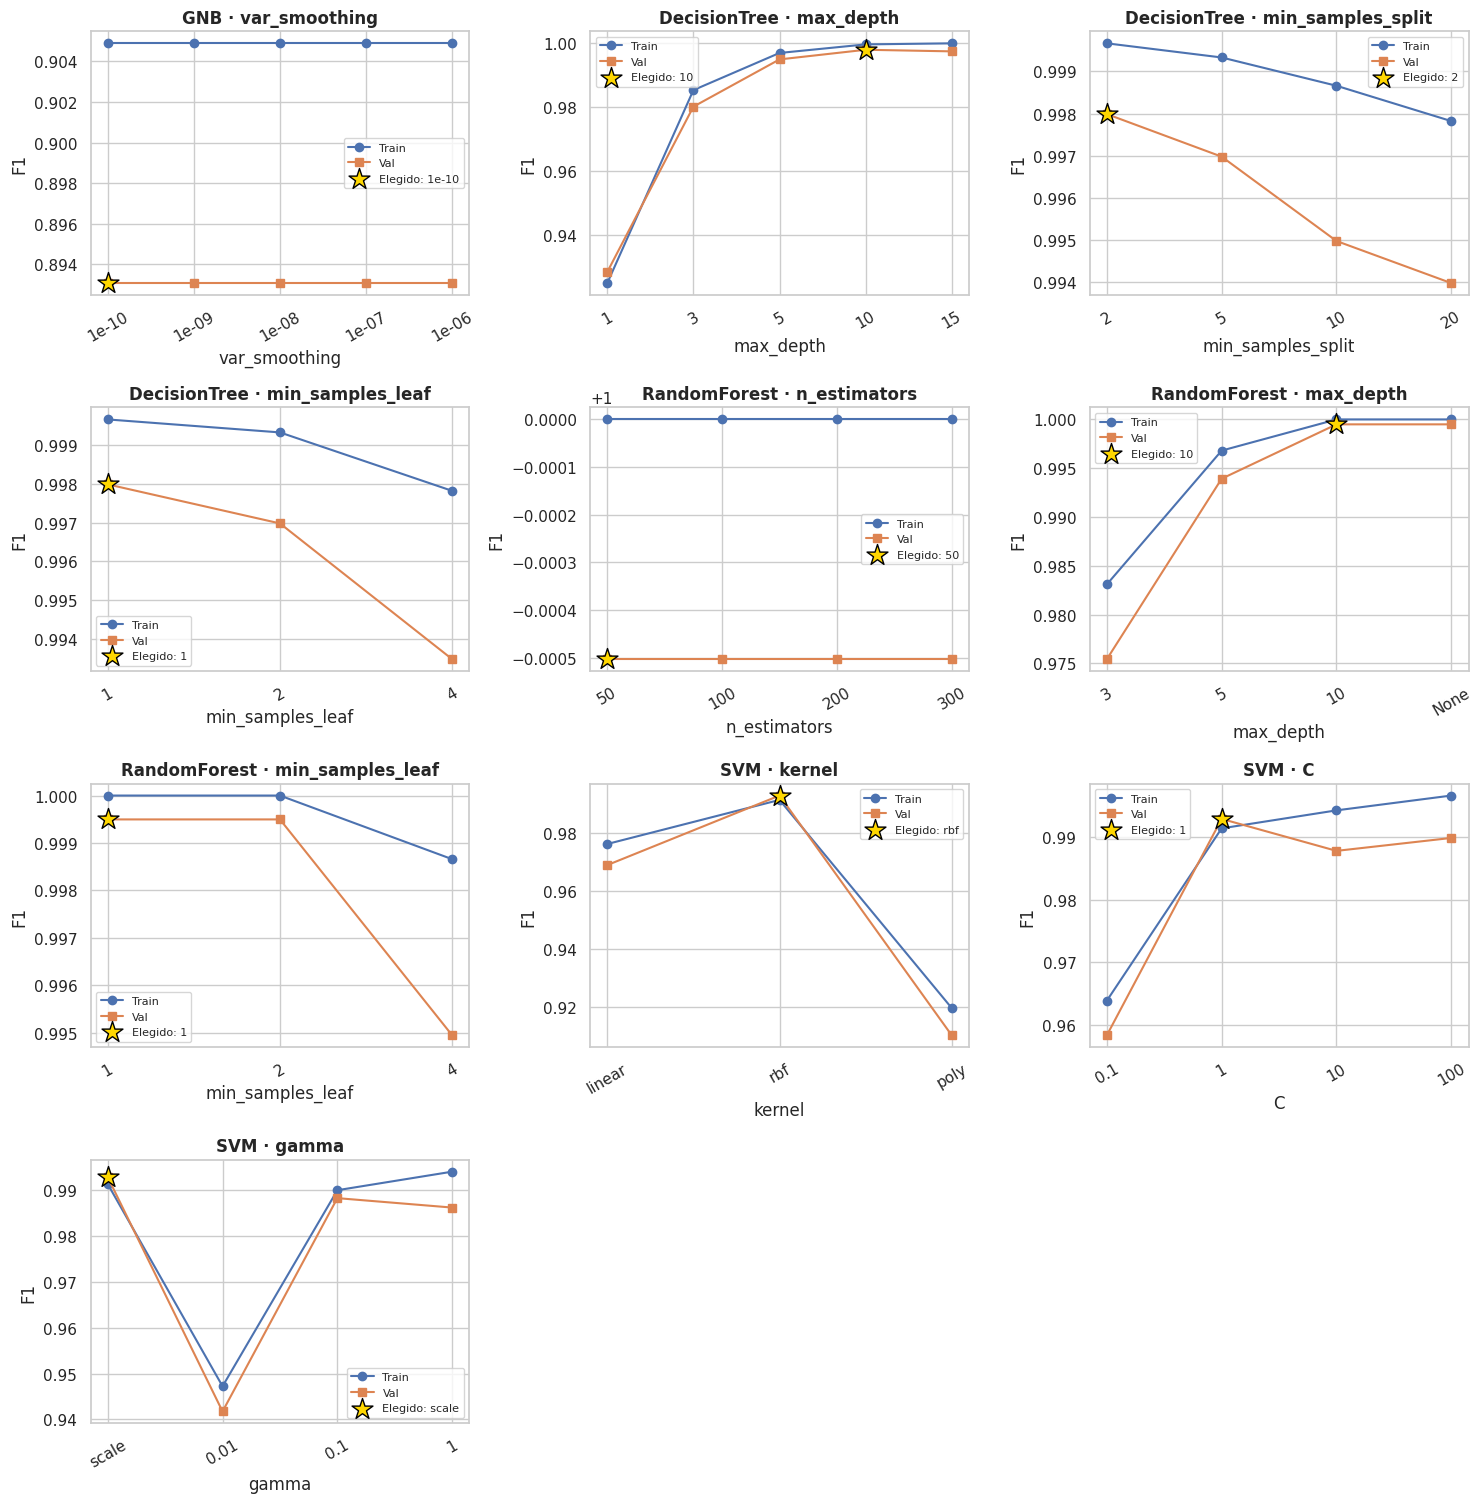

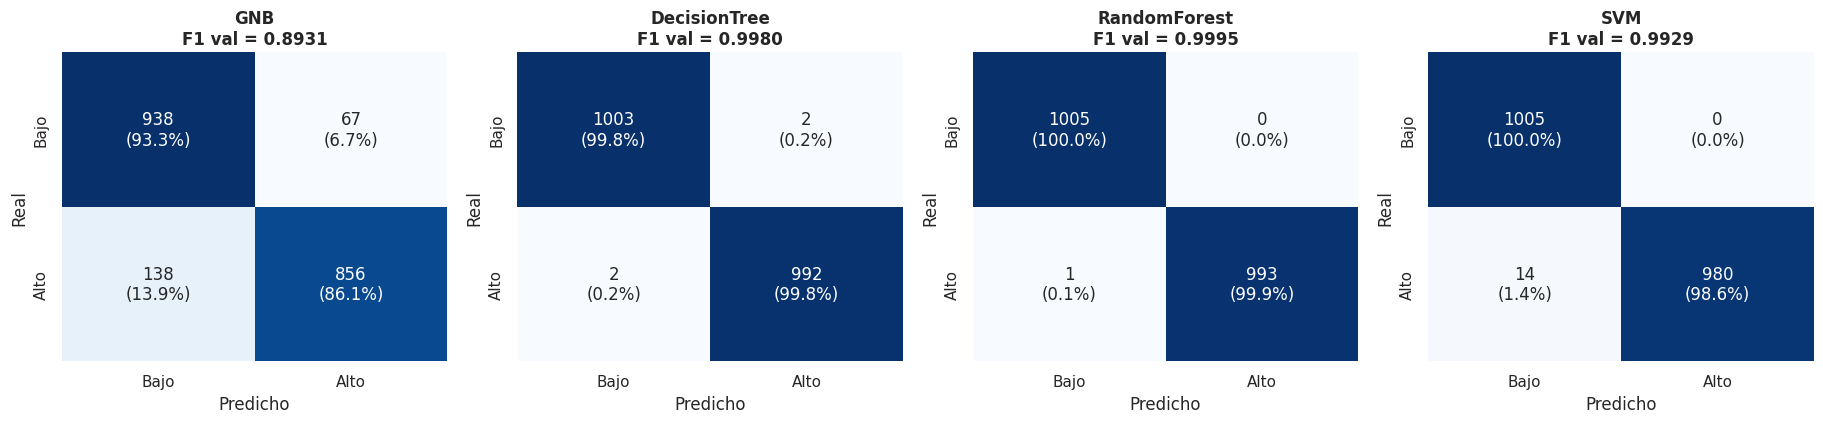

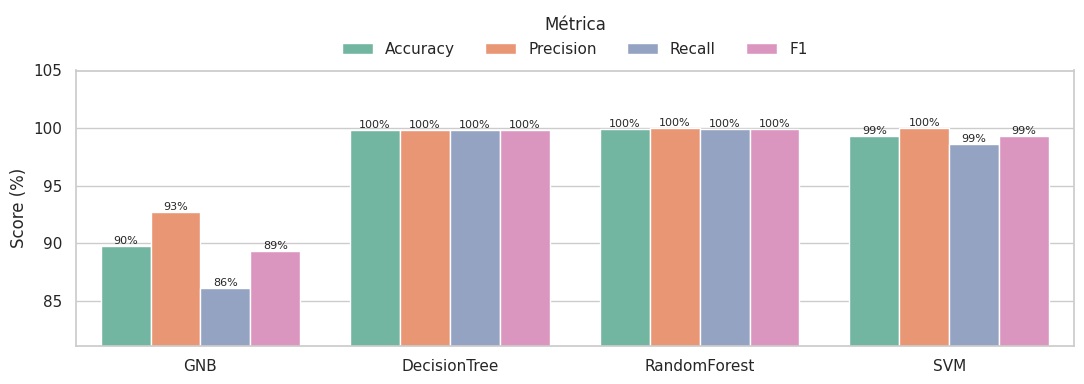

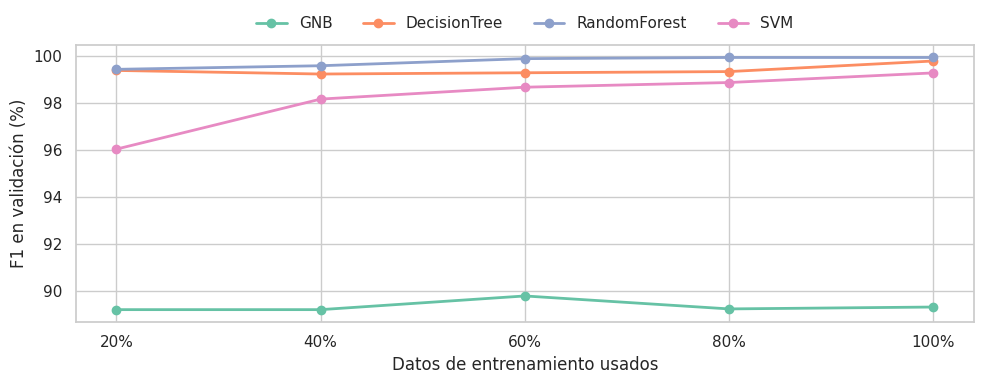

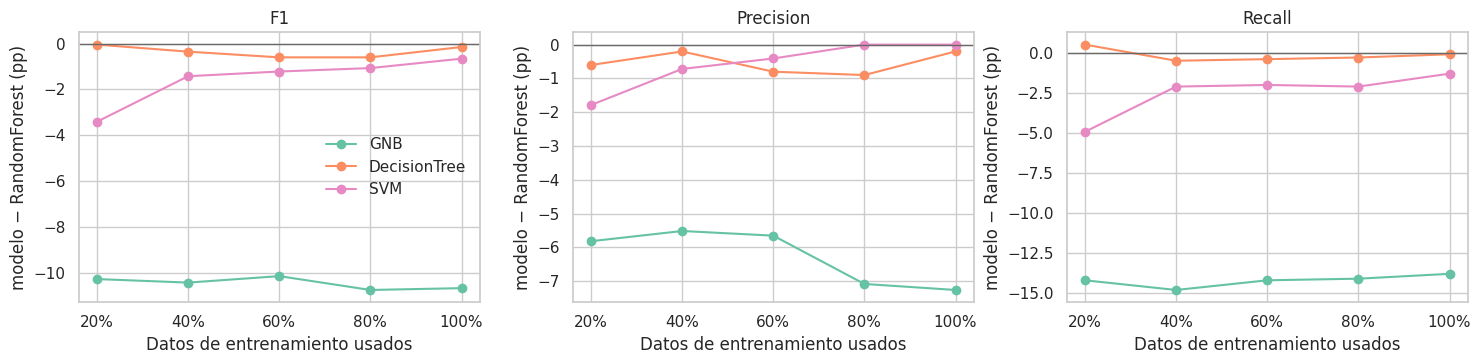

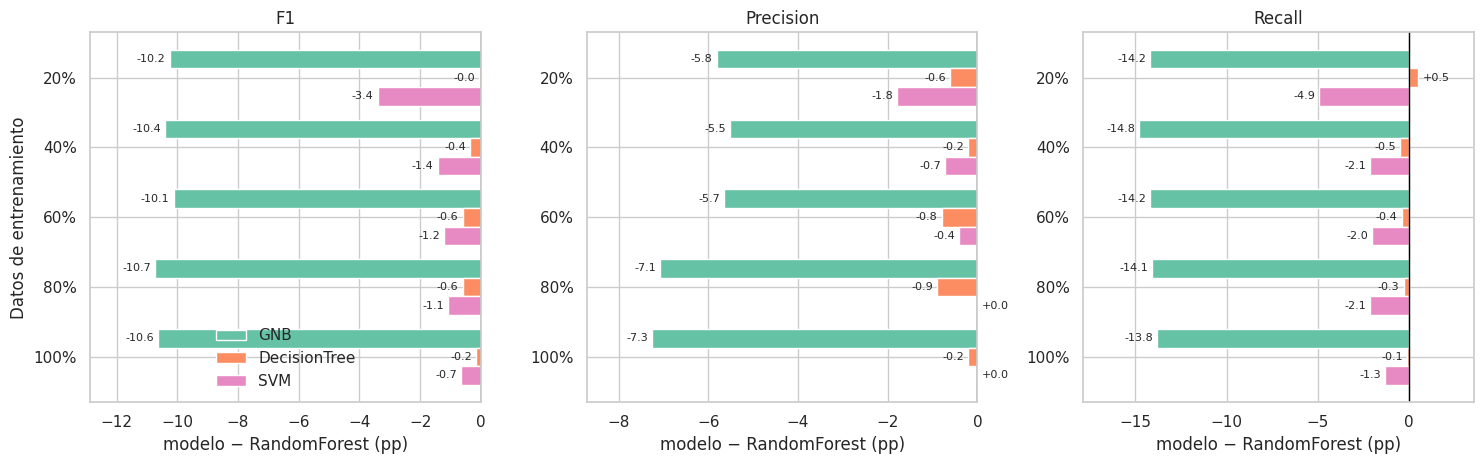

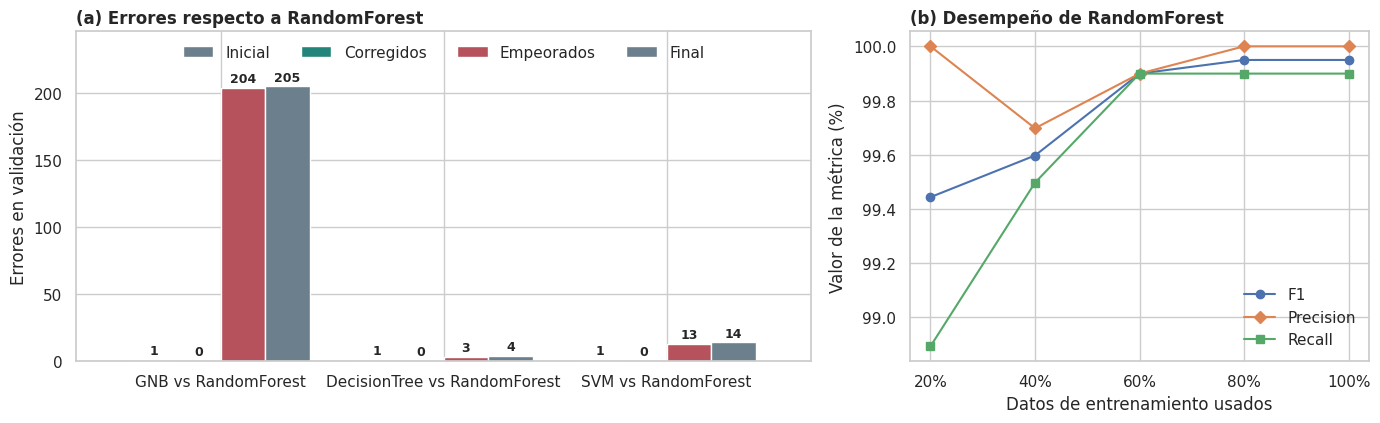

In [202]:
sns.set_theme(style="whitegrid")

MODELOS = [m for m in ["GNB", "DecisionTree", "RandomForest", "SVM"] if m in mejores]
BASE = "RandomForest"
OTROS = [m for m in MODELOS if m != BASE]
COLORES = dict(zip(MODELOS, sns.color_palette("Set2", len(MODELOS))))

pred_val = {n: construir(n, mejores[n]).fit(X_train, y_train).predict(X_val) for n in MODELOS}


# 10.1 Hiperparámetros: F1 en train vs validación
paneles = []
for n in MODELOS:
    intentos = df_resultados[df_resultados["Modelo"] == n]
    for hp, elegido in mejores[n].items():
        filas = []
        for _, f in intentos.iterrows():
            d = dict(p.split("=", 1) for p in f["Hiperparámetro"].split(", "))
            if list(d)[-1] == hp and all(str(mejores[n][k]) == v for k, v in d.items() if k != hp):
                filas.append((d[hp], f["Train_F1"], f["Val_F1"]))
        if filas:
            t = pd.DataFrame(filas, columns=["valor", "Train", "Val"]).drop_duplicates("valor")
            paneles.append((n, hp, str(elegido), t.reset_index(drop=True)))

cols = 3
fig, axes = plt.subplots(-(-len(paneles) // cols), cols, figsize=(15, 3.8 * -(-len(paneles) // cols)))
axes = axes.ravel()
for ax, (n, hp, elegido, t) in zip(axes, paneles):
    ax.plot(t["valor"], t["Train"], "o-", label="Train")
    ax.plot(t["valor"], t["Val"], "s-", label="Val")
    ax.scatter(elegido, t.loc[t["valor"] == elegido, "Val"], marker="*", s=250,
               color="gold", edgecolor="black", zorder=5, label=f"Elegido: {elegido}")
    ax.set_title(f"{n} · {hp}", fontweight="bold")
    ax.set_xlabel(hp)
    ax.set_ylabel("F1")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(fontsize=8)
for ax in axes[len(paneles):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


# 10.2 Matrices de confusión
def matriz(ax, y_real, y_pred, titulo):
    cm = confusion_matrix(y_real, y_pred, labels=[0, 1])
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    texto = np.array([[f"{cm[i, j]}\n({pct[i, j]:.1f}%)" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=texto, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Bajo", "Alto"], yticklabels=["Bajo", "Alto"])
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")

fig, axes = plt.subplots(1, len(MODELOS), figsize=(4.6 * len(MODELOS), 4.4))
for ax, n in zip(axes, MODELOS):
    matriz(ax, y_val, pred_val[n], f"{n}\nF1 val = {f1_score(y_val, pred_val[n]):.4f}")
plt.tight_layout()
plt.show()


# 10.3.1 Métricas por modelo (validación)
metricas = pd.DataFrame({
    n: {"Accuracy": accuracy_score(y_val, p) * 100,
        "Precision": precision_score(y_val, p, zero_division=0) * 100,
        "Recall": recall_score(y_val, p, zero_division=0) * 100,
        "F1": f1_score(y_val, p) * 100}
    for n, p in pred_val.items()}).T.rename_axis("Modelo").reset_index()
largo = metricas.melt(id_vars="Modelo", var_name="Métrica", value_name="Score")

fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=largo, x="Modelo", y="Score", hue="Métrica", palette="Set2", ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", fontsize=8)
ax.set_ylim(largo["Score"].min() - 5, 105)
ax.set_ylabel("Score (%)")
ax.set_xlabel("")
sns.move_legend(ax, "lower center", bbox_to_anchor=(0.5, 1), ncol=4, frameon=False)
plt.tight_layout()
plt.show()


# Curva de aprendizaje: entrenar con 20%, 40%... 100% del train
FRACCIONES = [20, 40, 60, 80, 100]
filas = []
for n in MODELOS:
    for fr in FRACCIONES:
        X_sub = X_train.sample(frac=fr / 100, random_state=42)
        p = construir(n, mejores[n]).fit(X_sub, y_train.loc[X_sub.index]).predict(X_val)
        filas.append({"Modelo": n, "Datos": fr,
                      "F1": f1_score(y_val, p) * 100,
                      "Precision": precision_score(y_val, p, zero_division=0) * 100,
                      "Recall": recall_score(y_val, p, zero_division=0) * 100})
curva = pd.DataFrame(filas)
METRICAS = ["F1", "Precision", "Recall"]


def eje_datos(ax):
    ax.set_xticks(FRACCIONES)
    ax.set_xticklabels([f"{f}%" for f in FRACCIONES])
    ax.set_xlabel("Datos de entrenamiento usados")


# 10.3.2 F1 vs cantidad de datos
fig, ax = plt.subplots(figsize=(10, 4))
for n in MODELOS:
    d = curva[curva["Modelo"] == n]
    ax.plot(d["Datos"], d["F1"], marker="o", linewidth=2, color=COLORES[n], label=n)
eje_datos(ax)
ax.set_ylabel("F1 en validación (%)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), ncol=len(MODELOS), frameon=False)
plt.tight_layout()
plt.show()


# Diferencia contra RandomForest (pp) por métrica
dif = {m: (lambda t: t.sub(t[BASE], axis=0)[OTROS])(curva.pivot(index="Datos", columns="Modelo", values=m))
       for m in METRICAS}

# 10.3.3 Diferencias en líneas
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True)
for ax, m in zip(axes, METRICAS):
    for n in OTROS:
        ax.plot(dif[m].index, dif[m][n], marker="o", color=COLORES[n], label=n)
    ax.axhline(0, color="dimgray", linewidth=1)
    ax.set_title(m)
    eje_datos(ax)
    ax.set_ylabel(f"modelo − {BASE} (pp)")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

# 10.3.4 Diferencias en barras horizontales
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, m in zip(axes, METRICAS):
    d = dif[m].rename(index=lambda i: f"{i}%")
    d.plot.barh(ax=ax, color=[COLORES[n] for n in OTROS], width=0.8, legend=False)
    for c in ax.containers:
        ax.bar_label(c, fmt="%+.1f", fontsize=8, padding=3)
    ax.axvline(0, color="black", linewidth=1)
    ax.invert_yaxis()
    ax.margins(x=0.2)
    ax.set_title(m)
    ax.set_xlabel(f"modelo − {BASE} (pp)")
    ax.set_ylabel("Datos de entrenamiento" if m == "F1" else "")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()


# 10.3.5 (a) Errores vs RandomForest  (b) Métricas del mejor modelo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})

y_real = np.array(y_val)
err_base = pred_val[BASE] != y_real
tabla = pd.DataFrame({
    n: {"Inicial": err_base.sum(),
        "Corregidos": (err_base & (pred_val[n] == y_real)).sum(),
        "Empeorados": (~err_base & (pred_val[n] != y_real)).sum(),
        "Final": (pred_val[n] != y_real).sum()}
    for n in OTROS}).T
tabla.plot.bar(ax=ax1, color=["#6C7F8C", "#23857A", "#B5525C", "#6C7F8C"], width=0.8, legend=False)
for c in ax1.containers:
    ax1.bar_label(c, fontsize=9, fontweight="bold", padding=2)
ax1.set_xticklabels([f"{n} vs {BASE}" for n in OTROS], rotation=0)
ax1.set_ylabel("Errores en validación")
ax1.set_title(f"(a) Errores respecto a {BASE}", loc="left", fontweight="bold")
ax1.legend(frameon=False, ncol=4, loc="upper center")
ax1.margins(y=0.2)

mejor = mejor_por_familia.iloc[0]["Modelo"]
d = curva[curva["Modelo"] == mejor]
for m, mk in zip(METRICAS, ["o", "D", "s"]):
    ax2.plot(d["Datos"], d[m], marker=mk, label=m)
eje_datos(ax2)
ax2.set_ylabel("Valor de la métrica (%)")
ax2.set_title(f"(b) Desempeño de {mejor}", loc="left", fontweight="bold")
ax2.legend(frameon=False)

plt.tight_layout()
plt.show()

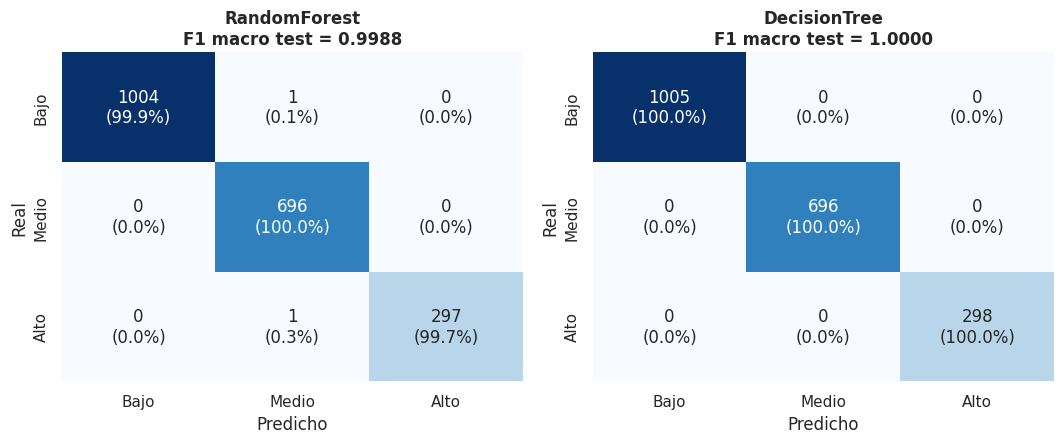

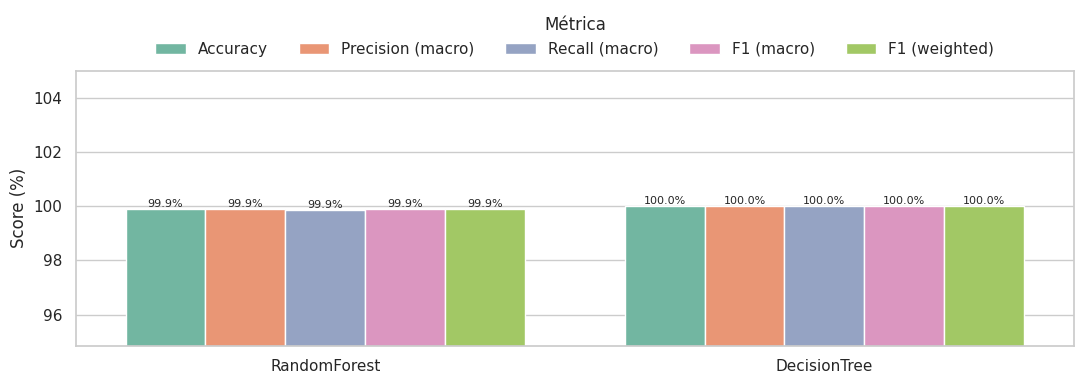

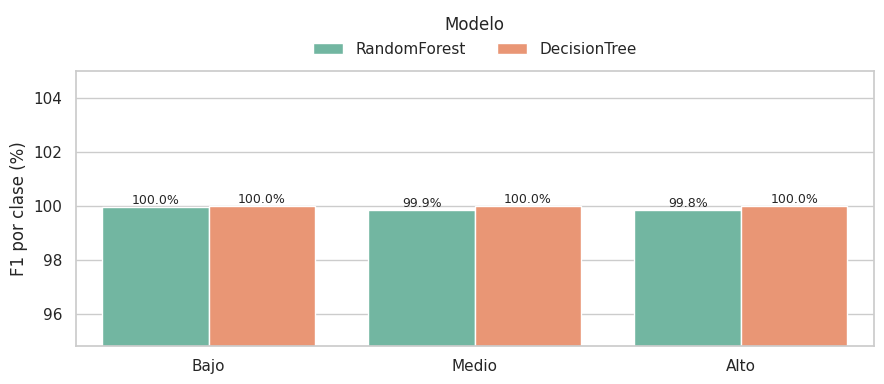

In [201]:
# --- (1) Matrices de confusión 3x3 de los 2 ganadores (test)
def matriz3(ax, y_real, y_pred, titulo):
    cm = confusion_matrix(y_real, y_pred, labels=[0, 1, 2])
    pct = cm / cm.sum(axis=1, keepdims=True) * 100            # % por fila (clase real)
    texto = np.array([[f"{cm[i, j]}\n({pct[i, j]:.1f}%)" for j in range(3)] for i in range(3)])
    sns.heatmap(cm, annot=texto, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=NOMBRES_CLASES, yticklabels=NOMBRES_CLASES)
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")

fig, axes = plt.subplots(1, len(ganadores), figsize=(5.4 * len(ganadores), 4.6))
for ax, n in zip(np.atleast_1d(axes), ganadores):
    f1m = f1_score(y_te_m, pred_multi[n], average="macro")
    matriz3(ax, y_te_m, pred_multi[n], f"{n}\nF1 macro test = {f1m:.4f}")
plt.tight_layout()
plt.show()


# --- (2) Métricas globales de los 2 modelos, lado a lado
largo = (comparacion * 100).reset_index().melt(id_vars="Modelo", var_name="Métrica", value_name="Score")
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=largo, x="Modelo", y="Score", hue="Métrica", palette="Set2", ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", fontsize=8)                  # valor sobre cada barra
ax.set_ylim(largo["Score"].min() - 5, 105)
ax.set_ylabel("Score (%)")
ax.set_xlabel("")
sns.move_legend(ax, "lower center", bbox_to_anchor=(0.5, 1), ncol=5, frameon=False)
plt.tight_layout()
plt.show()


# --- (3) F1 por clase: muestra en cuál clase falla cada modelo (normalmente "Medio")
por_clase = pd.DataFrame(
    {n: f1_score(y_te_m, pred_multi[n], average=None) * 100 for n in ganadores},
    index=NOMBRES_CLASES).rename_axis("Clase").reset_index().melt(
    id_vars="Clase", var_name="Modelo", value_name="F1")
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=por_clase, x="Clase", y="F1", hue="Modelo", palette="Set2", ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", fontsize=9)
ax.set_ylim(por_clase["F1"].min() - 5, 105)
ax.set_ylabel("F1 por clase (%)")
ax.set_xlabel("")
sns.move_legend(ax, "lower center", bbox_to_anchor=(0.5, 1), ncol=len(ganadores), frameon=False)
plt.tight_layout()
plt.show()